# IND320 Dashboard – del 4

Denne notebooken dokumenterer del 4 av IND320-prosjektet: valutakurser fra Norges Bank, tidssoner i datakildene, prognose av fyllingsgraden med River, og omstrukturering av Streamlit-appen med nye sider.

## Lenker
- GitHub-repository: https://github.com/Kaja321/ind320-dashboard-kaja321
- Publisert Streamlit-app: https://ind320-dashboard-kaja321.streamlit.app/
- Screencast: (legges inn til slutt)

## Bruk av kunstig intelligens
(skrives til slutt)

## Prosjektlogg
(skrives til slutt)

# Dataanalyse

## Valutakurser fra Norges Bank

Norges Bank har et åpent API for valutakurser. Adressen bygges slik:
`https://data.norges-bank.no/api/data/EXR/B.EUR+USD.NOK.SP`

- `EXR` er datasettet med valutakurser
- `B` betyr at kursene er daglige, men bare for virkedager (business days)
- `EUR+USD` er valutaene. Med `+` kan flere hentes i samme forespørsel
- `NOK` betyr at kursen er oppgitt i norske kroner (hvor mange kroner én euro koster)
- `SP` betyr spotkurs

Med `format=csv` kommer svaret som en tabell som pandas kan lese direkte. `locale=en` gir punktum som desimaltegn.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt


def download_exchange_rates(start_date, end_date, currencies=["EUR", "USD"]):
    """Laster ned daglige valutakurser mot norske kroner fra Norges Bank.

    start_date: første dag, f.eks. "2024-01-01"
    end_date:   siste dag, f.eks. "2024-12-31"
    currencies: liste med valutakoder, standard er euro og dollar

    Returnerer en tabell med dato som indeks og én kolonne per valuta (NOK per enhet).
    """
    # Valutakodene settes sammen med +, f.eks. "EUR+USD"
    codes = "+".join(currencies)
    url = (f"https://data.norges-bank.no/api/data/EXR/B.{codes}.NOK.SP"
           f"?format=csv&startPeriod={start_date}&endPeriod={end_date}&locale=en")

    # Norges Bank bruker semikolon mellom kolonnene i CSV-fila
    df = pd.read_csv(url, sep=";")

    # Svaret har én rad per dag og valuta. pivot gjør det om til én kolonne per valuta.
    # TIME_PERIOD er datoen, BASE_CUR er valutaen og OBS_VALUE er kursen.
    rates = df.pivot(index="TIME_PERIOD", columns="BASE_CUR", values="OBS_VALUE")

    # Datoformat på indeksen, og ryddige navn
    rates.index = pd.to_datetime(rates.index)
    rates.index.name = "date"
    rates.columns.name = None
    return rates

Antall dager: 251
          EUR     USD
count  251.00  251.00
mean    11.63   10.74
std      0.19    0.24
min     11.27   10.30
25%     11.45   10.55
50%     11.67   10.69
75%     11.77   10.95
max     12.11   11.42


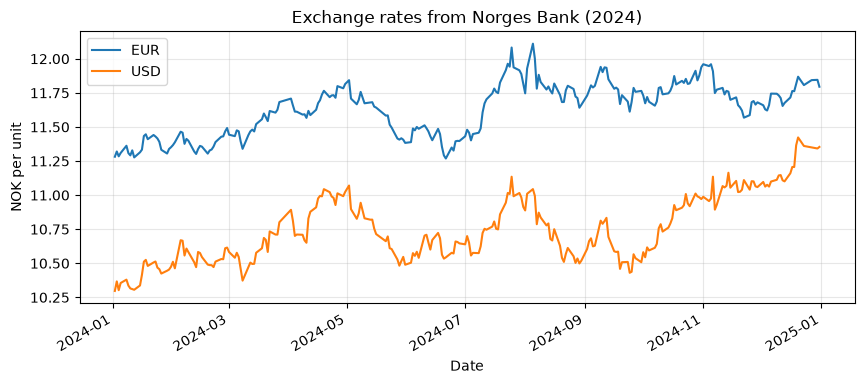

In [3]:
# Tester funksjonen for 2024, samme år som værdataene i del 3
rates = download_exchange_rates("2024-01-01", "2024-12-31")
print("Antall dager:", len(rates))   # rundt 250, fordi helger og helligdager mangler
print(rates.describe().round(2))

# Plotter begge kursene i samme figur
fig, ax = plt.subplots(figsize=(10, 4))
rates.plot(ax=ax)
ax.set_title("Exchange rates from Norges Bank (2024)")
ax.set_xlabel("Date")
ax.set_ylabel("NOK per unit")
ax.grid(alpha=0.3)
plt.show()

Funksjonen virker: den henter 251 dager for 2024, med kurser for både euro og dollar. Det er bare virkedager, fordi Norges Bank ikke publiserer kurser i helger og på helligdager. Når kursene skal brukes sammen med magasinstatistikken, som er ukentlig, må de derfor gjøres om til samme tidsoppløsning, for eksempel gjennomsnitt per uke.

## Tidssoner i datakildene

Datakildene oppgir tid på ulike måter. Noen bruker UTC, noen bruker norsk tid, og noen oppgir bare dato uten klokkeslett. Hvis dataene kobles sammen uten å ta hensyn til dette, kan verdier havne på feil time eller feil dag. Norsk tid er UTC+1 om vinteren og UTC+2 om sommeren (sommertid), så forskjellen er én eller to timer. Ved overgangen til sommertid mangler én time, og ved overgangen til vintertid kommer én time to ganger.

Under sjekkes hver kilde for seg.

In [4]:
import requests

# Henter magasinstatistikken (trengs også senere til prognosen)
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
reservoirs = pd.DataFrame(requests.get(url).json())

# Viser datoen slik den kommer fra APIet, før den gjøres om
print("Rå verdi fra APIet:", reservoirs["dato_Id"].iloc[0])

reservoirs["dato_Id"] = pd.to_datetime(reservoirs["dato_Id"])
reservoirs["area"] = reservoirs["omrType"] + " " + reservoirs["omrnr"].astype(str)
print("Tidssone:", reservoirs["dato_Id"].dt.tz)   # None betyr at ingen tidssone er oppgitt

# Hvilken ukedag datoene faller på
print(reservoirs["dato_Id"].dt.day_name().value_counts())
reservoirs[["dato_Id", "iso_aar", "iso_uke"]].head()

Rå verdi fra APIet: 2020-11-15
Tidssone: None
dato_Id
Sunday    14967
Name: count, dtype: int64


,dato_Id,iso_aar,iso_uke
0,2020-11-15,2020,46
1,2011-08-28,2011,34
2,1998-07-05,1998,27
3,2011-03-27,2011,12
4,2017-11-05,2017,44


In [6]:
import tomllib
import pymongo

# Leser MongoDB-adressen fra secrets.toml, så adressen ikke står i notebooken
with open("../.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)
client = pymongo.MongoClient(secrets["mongo"]["uri"])

# Henter bare noen få rader, det holder for å se tidsformatet
flows = pd.DataFrame(list(client["ind320"]["flows"].find({}, {"_id": 0}).limit(5)))
print(flows.dtypes)
flows.head()

connection               str
direction                str
time          datetime64[us]
flow_mw              float64
dtype: object


,connection,direction,time,flow_mw
0,NO_2-DE_LU,export,2024-10-14 22:00:00,1352.48
1,NO_2-DE_LU,export,2024-10-14 23:00:00,1271.00
2,NO_2-DE_LU,export,2024-10-15 09:00:00,1049.28
3,NO_2-DE_LU,export,2024-10-15 13:00:00,1404.00
4,NO_2-DE_LU,export,2024-10-15 15:00:00,1404.84


In [ ]:
import openmeteo_requests

# Klienten sender forespørsler til open-meteo (som i download_weather, men uten cache og retry,
# fordi vi bare henter litt data for å se på tidsformatet)
openmeteo = openmeteo_requests.Client()
# Ett punkt i Oslo og én dag er nok. 1. juli er sommertid, så forskjellen mellom
# UTC og norsk tid er 2 timer og lett å se.
params = {"latitude": 59.91, "longitude": 10.75,   # Oslo
          "start_date": "2024-07-01", "end_date": "2024-07-01",
          "hourly": "temperature_2m", "models": "era5"}

# Uten timezone-parameter (slik funksjonen i del 3 gjør det)
response = openmeteo.weather_api("https://archive-api.open-meteo.com/v1/archive", params=params)[0]
print("Standard:     ", response.Timezone(), "– forskyvning", response.UtcOffsetSeconds() / 3600, "timer")

# Med norsk tidssone
params["timezone"] = "Europe/Oslo"
response = openmeteo.weather_api("https://archive-api.open-meteo.com/v1/archive", params=params)[0]
print("Europe/Oslo:  ", response.Timezone(), "– forskyvning", response.UtcOffsetSeconds() / 3600, "timer")

Standard:      None – forskyvning 0.0 timer
Europe/Oslo:   b'Europe/Oslo' – forskyvning 1.0 timer


In [10]:
# MongoDB gir tidene uten tidssone. tz_localize sier at de er i UTC,
# og tz_convert regner dem om til norsk tid (med sommertid).
flows["time_utc"] = flows["time"].dt.tz_localize("UTC")
flows["time_oslo"] = flows["time_utc"].dt.tz_convert("Europe/Oslo")
flows[["time_utc", "time_oslo"]].head()

,time_utc,time_oslo
0,2024-10-14 22:00:00+00:00,2024-10-15 00:00:00+02:00
1,2024-10-14 23:00:00+00:00,2024-10-15 01:00:00+02:00
2,2024-10-15 09:00:00+00:00,2024-10-15 11:00:00+02:00
3,2024-10-15 13:00:00+00:00,2024-10-15 15:00:00+02:00
4,2024-10-15 15:00:00+00:00,2024-10-15 17:00:00+02:00


In [8]:
# rates ble lastet ned over. Sjekker tidssone og ukedager.
print("Tidssone:", rates.index.tz)
print(rates.index.day_name().value_counts())

Tidssone: None
date
Tuesday      52
Wednesday    50
Friday       50
Monday       50
Thursday     49
Name: count, dtype: int64


### Funn og løsning

**Magasinstatistikk (NVE)** har ukentlige verdier med bare dato og ingen tidssone. Datoen er alltid en søndag, altså siste dag i uka.

**ENTSO-E** har timesverdier i UTC. Dataene starter 14. oktober 2024 kl. 22:00, som er midnatt 15. oktober norsk tid. Når dataene leses fra MongoDB, forsvinner tidssonen, så den må settes tilbake med `tz_localize("UTC")`.

**open-meteo** gir timesverdier i UTC hvis man ikke velger noe annet. Med `timezone="Europe/Oslo"` ble forskyvningen oppgitt som 1 time for 1. juli, selv om det var sommertid (2 timer). Det er tryggere å hente dataene i UTC og regne om selv.

**Norges Bank** har bare dato, ingen tidssone, og bare virkedager. Kursene publiseres rundt kl. 16 norsk tid.

**Løsning:** Timesdata holdes i UTC, så sommertid ikke lager timer som mangler eller kommer to ganger. Når timesdata skal kobles med NVE eller Norges Bank, regnes tidene først om til norsk tid med `tz_convert("Europe/Oslo")`. Deretter brukes gjennomsnittet for hver uke som slutter på søndag (`resample("W-SUN")`), så ukene passer med magasinstatistikken. Det løser også at valutakursene mangler helger.

## Områdene som GeoJSON

Shapefilene fra del 3 gjøres om til GeoJSON, slik at kartet i appen kan bruke dem uten geopandas. Kantene forenkles for å gjøre filene mindre og kartet raskere, og koordinatene gjøres om til lengde- og breddegrad, som GeoJSON bruker.

In [11]:
import os
import geopandas as gpd

# Leser shapefilene, som i del 3
regions = gpd.read_file("../data/NVE_Region/NVE_Region.shp", encoding="utf-8")
bid_zones = gpd.read_file("../data/Budomrader/Budomrader.shp")

# Vassdragsområdene: NVE-regionene slås sammen (RS + RØ = VASS 1, RV = VASS 2, RM + RN = VASS 3)
region_to_area = {"RS": "VASS 1", "RØ": "VASS 1",
                  "RV": "VASS 2",
                  "RM": "VASS 3", "RN": "VASS 3"}
regions["area"] = regions["REGION"].map(region_to_area)
vass_areas = regions.dissolve(by="area").reset_index()[["area", "geometry"]]

# Strømprisområdene: "NO 1" blir "EL 1", så navnene passer med magasinstatistikken
bid_zones["area"] = bid_zones["budomr"].str.replace("NO", "EL")
el_areas = bid_zones[["area", "geometry"]]

# Lagrer hver områdetype som en egen GeoJSON-fil
for name, areas in [("price_areas", el_areas), ("water_areas", vass_areas)]:
    areas = areas.copy()
    # Forenkler kantene. 1000 er i meter, fordi dataene fortsatt er i UTM33.
    areas["geometry"] = areas.simplify(1000)
    # Gjør om til lengde- og breddegrad, som GeoJSON og Plotly bruker
    areas = areas.to_crs(epsg=4326)
    path = f"../data/{name}.geojson"
    areas.to_file(path, driver="GeoJSON")
    # Viser filstørrelsen, så vi ser at filene ikke er for store
    print(path, round(os.path.getsize(path) / 1e6, 2), "MB")

../data/price_areas.geojson 0.04 MB
../data/water_areas.geojson 0.06 MB


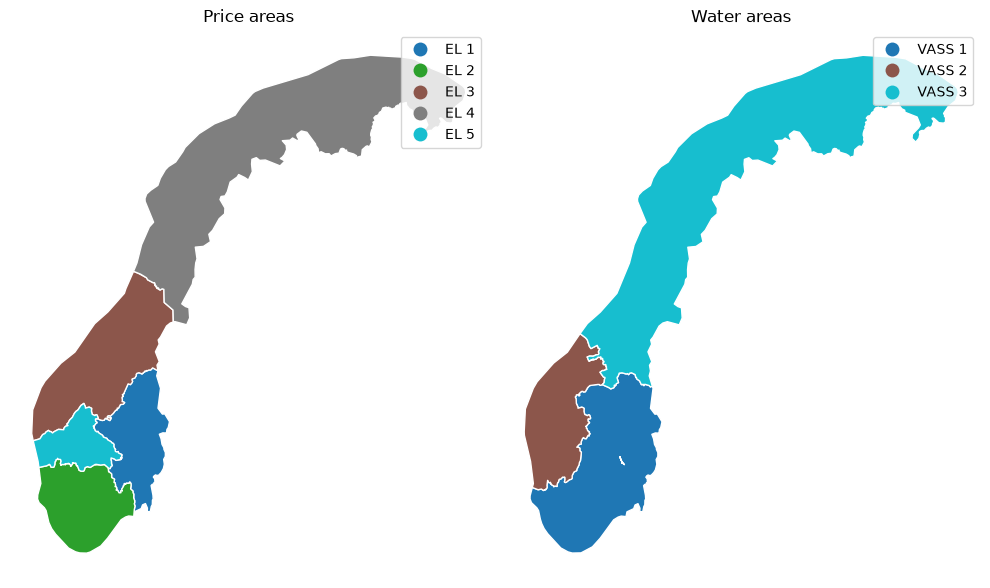

In [14]:
import matplotlib.pyplot as plt

# Leser GeoJSON-filene tilbake og tegner dem, for å sjekke at forenklingen ikke ødela områdene
fig, axs = plt.subplots(1, 2, figsize=(10, 6))
for ax, name in zip(axs, ["price_areas", "water_areas"]):
    areas = gpd.read_file(f"../data/{name}.geojson")
    areas.plot(column="area", ax=ax, legend=True, edgecolor="white", cmap="tab10")
    ax.set_title(name.replace("_", " ").capitalize())
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## Skisse av appen

Før appen ble endret, ble sidene organisert etter type oppgave: oversikt over dataene (Overview), analyse av mønstre og avvik (Analysis), og prognose (Prediction). Home er forsiden. Gruppene vises som overskrifter i menyen.

Området er et felles valg som huskes mellom sidene med `st.session_state`. Tiden som velges i kartet brukes som treningsperiode i prognosen. År og periode velges ellers lokalt på sidene der det gir mer mening.

![App structure](sketch.png)